# 01 · Modbus TCP na prática

**Objetivo:** entender as quatro tabelas do Modbus, os function codes e como um cliente fecha uma malha de controle lendo e escrevendo registradores.

**O que você vai ver**
1. Subir um servidor Modbus que simula um tanque com bomba
2. Ler cada tabela separadamente e olhar o valor *cru* que vem do equipamento
3. Aplicar a escala (x10) para virar unidade de engenharia
4. Escrever um setpoint (FC06) e uma bobina (FC05)
5. Rodar um controle liga/desliga com histerese e observar o nível subir

> Modbus nasceu em 1979 (Modicon) e continua sendo o protocolo mais comum em chão de fábrica, justamente por ser simples: o mestre pergunta, o escravo responde, e tudo são bits ou palavras de 16 bits.

In [1]:
# Configuração: deixa a raiz do repositório no caminho de import
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
from common.notebook import load, run_in_background, require_broker

## 1. O mapa de registradores

Todo equipamento Modbus vem com uma **tabela de endereços** no manual. Sem ela, os números não significam nada. O do nosso tanque:

| Tabela | Tamanho | Acesso | Function code | Endereço | Significado |
|---|---|---|---|---|---|
| Coils | 1 bit | leitura/escrita | 01 lê, 05 escreve | 0 | comando da bomba |
| Discrete inputs | 1 bit | só leitura | 02 | 0, 1 | chave de nível alto, retorno da bomba |
| Input registers | 16 bits | só leitura | 04 | 0, 1 | nível x10, temperatura x10 |
| Holding registers | 16 bits | leitura/escrita | 03 lê, 06 escreve | 0, 1 | setpoint x10, abertura da válvula |

**Pegadinha clássica:** manuais escrevem "40001" para o holding register 0. O "4" indica a tabela e o "0001" é base 1. No protocolo vai o endereço **0**.

In [2]:
# Sobe o servidor do tanque em segundo plano (porta 5020, não precisa de admin)
plant = load("01-modbus-tcp-basics/plant_server.py")
run_in_background(lambda: plant.main(port=5020), port=5020)

servidor ativo na porta 5020


## 2. Lendo cada tabela, um function code por vez

Cada leitura abaixo é **uma requisição separada na rede**. Repare no formato do que volta: bits viram `True/False`, registradores viram inteiros de 0 a 65535.

In [3]:
from pymodbus.client import ModbusTcpClient

c = ModbusTcpClient("localhost", port=5020)
c.connect()

coils = c.read_coils(0, count=1, slave=1)              # FC01
di    = c.read_discrete_inputs(0, count=2, slave=1)    # FC02
hr    = c.read_holding_registers(0, count=2, slave=1)  # FC03
ir    = c.read_input_registers(0, count=2, slave=1)    # FC04

print("FC01 coils            ->", coils.bits[:1])
print("FC02 discrete inputs  ->", di.bits[:2])
print("FC03 holding regs     ->", hr.registers)
print("FC04 input regs       ->", ir.registers)

FC01 coils            -> [False]
FC02 discrete inputs  -> [False, False]
FC03 holding regs     -> [600, 30]
FC04 input regs       -> [499, 220]


**Como ler o resultado**

* `coils` mostra `[False]`: a bomba está desligada.
* `holding regs` traz `[600, 30]`: setpoint **60,0 %** (600 / 10) e válvula de saída **30 %**.
* `input regs` traz algo como `[500, 220]`: nível **50,0 %** e temperatura **22,0 °C**.

O equipamento **nunca manda casas decimais**. A convenção "x10" está no manual, e é o cliente que divide. Se você esquecer a escala, o SCADA mostra 500 % de nível.

In [4]:
# Escala: valor cru -> unidade de engenharia
nivel = ir.registers[0] / 10
temp  = ir.registers[1] / 10
sp    = hr.registers[0] / 10
print(f"nível = {nivel:.1f} %   temperatura = {temp:.1f} °C   setpoint = {sp:.1f} %")

nível = 49.9 %   temperatura = 22.0 °C   setpoint = 60.0 %


## 3. Escrevendo: setpoint (FC06) e bomba (FC05)

Escrever é igualmente simples. Só as tabelas **coils** e **holding registers** aceitam escrita: tentar escrever num input register daria erro, porque ele representa uma medição.

In [5]:
c.write_register(0, 700, slave=1)   # FC06: setpoint 70,0 %
c.write_coil(0, True, slave=1)      # FC05: liga a bomba
import time; time.sleep(1)

print("setpoint agora :", c.read_holding_registers(0, count=1, slave=1).registers[0] / 10, "%")
print("bomba comandada:", c.read_coils(0, count=1, slave=1).bits[0])
print("bomba rodando  :", c.read_discrete_inputs(1, count=1, slave=1).bits[0], "(retorno do campo)")
c.write_coil(0, False, slave=1)     # desliga de novo para o próximo passo
c.close()

setpoint agora : 70.0 %
bomba comandada: True
bomba rodando  : True (retorno do campo)


Repare na diferença entre **comando** (coil 0, o que pedimos) e **retorno** (discrete input 1, o que o equipamento confirma). Em sistemas reais os dois podem divergir: contator travado, disjuntor desarmado. Por isso sempre se lê o retorno.

## 4. Fechando a malha: controle liga/desliga com histerese

O cliente do exemplo faz o que um CLP ou um gateway de borda faria: lê o nível, compara com o setpoint e liga ou desliga a bomba. A **histerese** (banda de ±2 %) evita que a bomba fique ligando e desligando a cada leitura.

In [6]:
client = load("01-modbus-tcp-basics/client.py")
historico = client.run(seconds=28, port=5020)

level  51.1 %  SP 70.0 %  pump ON   temp 22.1 C


level  52.3 %  SP 70.0 %  pump ON   temp 22.1 C


level  53.5 %  SP 70.0 %  pump ON   temp 22.2 C


level  54.7 %  SP 70.0 %  pump ON   temp 22.2 C


level  55.9 %  SP 70.0 %  pump ON   temp 22.2 C


level  57.1 %  SP 70.0 %  pump ON   temp 22.3 C


... (18 outputs left out)

level  70.9 %  SP 70.0 %  pump off  temp 22.3 C


level  70.6 %  SP 70.0 %  pump off  temp 22.2 C


level  70.3 %  SP 70.0 %  pump off  temp 22.2 C


level  70.0 %  SP 70.0 %  pump off  temp 22.2 C


**Interpretação**

* No início o nível (cerca de 50 %) está abaixo de `SP - 2 %` = 68 %, então o controle liga a bomba (`pump ON`).
* O nível sobe cerca de **1,2 % por segundo**: a bomba coloca 1,5 %/s e a válvula de 30 % tira 0,3 %/s.
* Quando passar de `SP + 2 %` (72 %), a bomba desliga e o nível começa a cair devagar.

Abaixo, o mesmo histórico em gráfico.

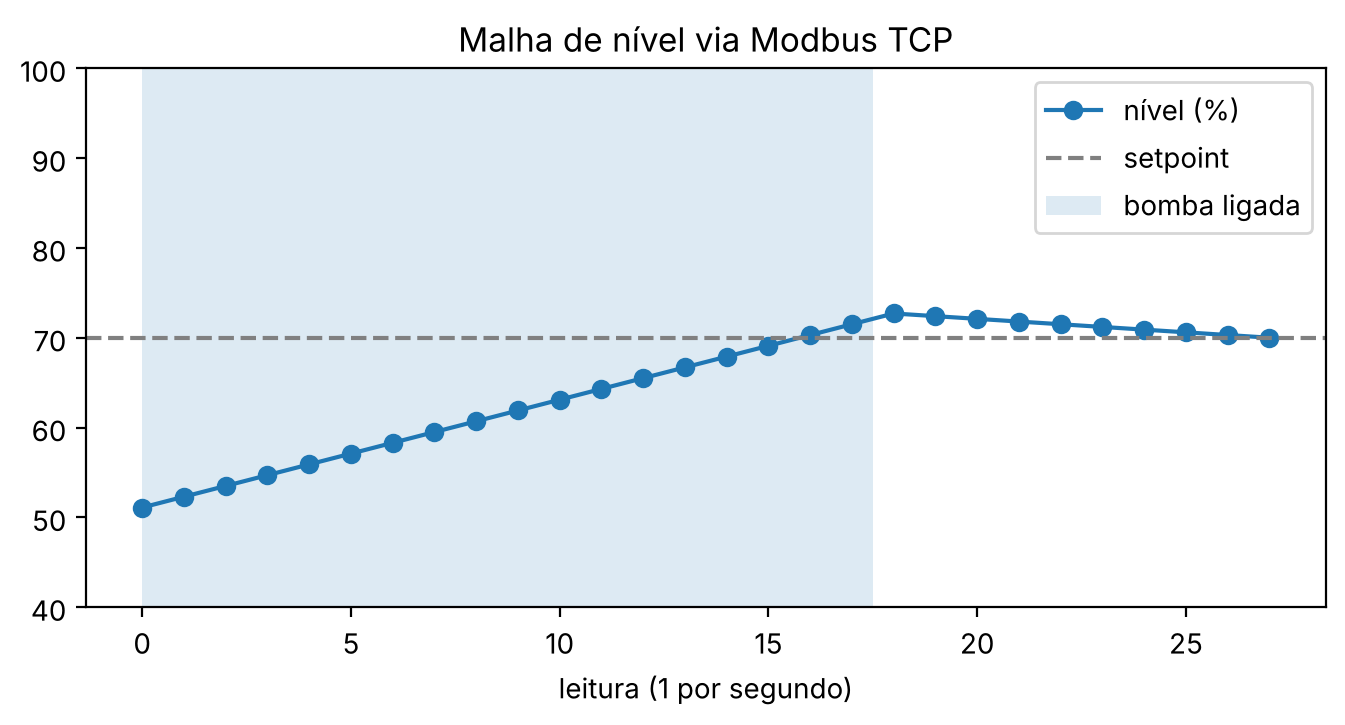

In [7]:
import matplotlib.pyplot as plt
t = range(len(historico))
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t, [h["level_pct"] for h in historico], marker="o", label="nível (%)")
ax.axhline(historico[0]["setpoint_pct"], ls="--", color="gray", label="setpoint")
ax.fill_between(t, [h["pump_cmd"] * 100 for h in historico], alpha=0.15, step="mid", label="bomba ligada")
ax.set_ylim(40, 100); ax.set_xlabel("leitura (1 por segundo)"); ax.legend(); ax.set_title("Malha de nível via Modbus TCP")
plt.show()

## Resumo

* Modbus tem **4 tabelas**, e o tipo de dado (bit ou palavra) e o acesso (leitura ou escrita) vêm da tabela, não do valor.
* O endereço no protocolo é **base 0**; "40001" é notação de documentação.
* **Escala** e unidade são convenção do fabricante: sem o mapa de registradores, os números não significam nada.
* O cliente consegue fechar uma malha de controle simples, mas a lógica de segurança deve ficar no CLP, não no cliente.

**Próximo:** o notebook 02 mostra como 32 bits, floats e negativos cabem (ou não) em registradores de 16 bits.